In [1]:
!pip install -q pandas numpy datasets shap joblib

In [2]:
import os
import json

import joblib
import numpy as np
import pandas as pd
import shap

from datasets import load_dataset
from sklearn.model_selection import train_test_split

print('All imports OK')

All imports OK


In [3]:
model = joblib.load('LightGBM.pkl')
le    = joblib.load('label_encoder.pkl')

print('Model loaded :', type(model).__name__)
print('Classes      :', list(le.classes_))

Model loaded : LGBMClassifier
Classes      : ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']


In [4]:
dataset = load_dataset('bvsam/cic-ids-2017', 'machine_learning', split='train')
df = dataset.to_pandas()

print(f'Shape: {df.shape}')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

machine_learning/Friday-WorkingHours-Aft(…):   0%|          | 0.00/22.2M [00:00<?, ?B/s]

machine_learning/Friday-WorkingHours-Aft(…):   0%|          | 0.00/15.7M [00:00<?, ?B/s]

machine_learning/Friday-WorkingHours-Mor(…):   0%|          | 0.00/19.4M [00:00<?, ?B/s]

machine_learning/Monday-WorkingHours.pca(…):   0%|          | 0.00/57.0M [00:00<?, ?B/s]

... (2 outputs left out)

machine_learning/Tuesday-WorkingHours.pc(…):   0%|          | 0.00/45.6M [00:00<?, ?B/s]

machine_learning/Wednesday-workingHours.(…):   0%|          | 0.00/67.4M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2830743 [00:00<?, ? examples/s]

Shape: (2830743, 79)


In [5]:
X = df.drop(columns=['Label'])
y = df['Label']

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

y_enc = le.transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc,
    test_size=0.2,
    stratify=y_enc,
    random_state=42
)

y_test = pd.Series(y_test, index=X_test.index)

print(f'Test size: {X_test.shape[0]:,}')

Test size: 566,149


In [6]:
CLASSES_TO_ANALYZE = ['DoS Hulk', 'PortScan', 'Bot', 'BENIGN', 'DDoS']

samples = []
for label in CLASSES_TO_ANALYZE:
    class_id = le.transform([label])[0]
    idx = np.where(y_test == class_id)[0][:5]
    samples.append(X_test.iloc[idx])

X_eval = pd.concat(samples)
y_eval = y_test.loc[X_eval.index]

print(f'Eval samples: {X_eval.shape[0]} ({len(CLASSES_TO_ANALYZE)} kelas × 5 sampel)')

Eval samples: 25 (5 kelas × 5 sampel)


In [7]:
explainer   = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_eval)

print('SHAP values shape:', np.array(shap_values).shape)

SHAP values shape: (25, 78, 15)


In [8]:
label_names = list(le.classes_)
results     = {}

for label in CLASSES_TO_ANALYZE:
    class_id  = le.transform([label])[0]
    class_idx = label_names.index(label)

    mask           = (y_eval == class_id)
    shap_for_class = shap_values[mask, :, class_idx]   # (n_samples, n_features)

    if shap_for_class.shape[0] == 0:
        print(f'⚠️ No samples for {label}')
        continue

    mean_signed = shap_for_class.mean(axis=0)
    mean_abs    = np.abs(shap_for_class).mean(axis=0)
    top_idx     = mean_abs.argsort()[::-1][:5]

    top5 = pd.DataFrame({
        'Feature'  : X_eval.columns[top_idx],
        'Mean SHAP': mean_signed[top_idx],
        'Abs SHAP' : mean_abs[top_idx],
        'Direction': ['↑ increase' if v > 0 else '↓ decrease'
                      for v in mean_signed[top_idx]],
    }).round(4).astype({'Mean SHAP': float, 'Abs SHAP': float})

    results[label] = top5

    print(f'\n=== {label} ===')
    for _, row in top5.iterrows():
        print(f"  {row['Feature']:<35} | {row['Mean SHAP']:>8.4f} | {row['Direction']}")


=== DoS Hulk ===
  Init_Win_bytes_forward              |   1.7485 | ↑ increase
  FIN Flag Count                      |   0.9924 | ↑ increase
  Bwd Packets/s                       |   0.9074 | ↑ increase
  Fwd IAT Std                         |   0.8885 | ↑ increase
  Total Length of Bwd Packets         |   0.8568 | ↑ increase

=== PortScan ===
  Packet Length Mean                  |   2.7775 | ↑ increase
  Bwd Packet Length Min               |   2.0878 | ↑ increase
  Flow Bytes/s                        |   1.2642 | ↑ increase
  PSH Flag Count                      |   1.2616 | ↑ increase
  Init_Win_bytes_forward              |   1.1709 | ↑ increase

=== Bot ===
  Destination Port                    |   7.0308 | ↑ increase
  min_seg_size_forward                |   0.7749 | ↑ increase
  Flow IAT Min                        |   0.7067 | ↑ increase
  Init_Win_bytes_backward             |   0.5631 | ↑ increase
  Bwd Packet Length Max               |  -0.3207 | ↓ decrease

=== BENIGN ===
  Ini

In [9]:
export = {label: df_top.to_dict(orient='records') for label, df_top in results.items()}

with open('shap_per_class.json', 'w') as f:
    json.dump(export, f, indent=2)

print('Saved: shap_per_class.json')

Saved: shap_per_class.json


In [10]:
X_sample = X.sample(5000, random_state=42)

shap_values_global = explainer.shap_values(X_sample)

print('Shape:', np.array(shap_values_global).shape)

Shape: (5000, 78, 15)


In [11]:
mean_shap      = np.abs(shap_values_global).mean(axis=(0, 2))
feat_importance = pd.Series(mean_shap, index=X_sample.columns)

print('Top-15 Global Feature Importance:')
print(feat_importance.sort_values(ascending=False).head(15))

Top-15 Global Feature Importance:
Flow IAT Mean              1.320405
Flow IAT Min               1.028378
Bwd Packets/s              0.781534
Fwd Header Length          0.763099
Init_Win_bytes_forward     0.663161
Active Max                 0.489485
Init_Win_bytes_backward    0.416121
Destination Port           0.412136
Fwd IAT Std                0.384577
Fwd IAT Min                0.222668
Idle Min                   0.216768
Flow Duration              0.209648
min_seg_size_forward       0.188807
Active Min                 0.179783
Bwd Packet Length Min      0.090968
dtype: float64


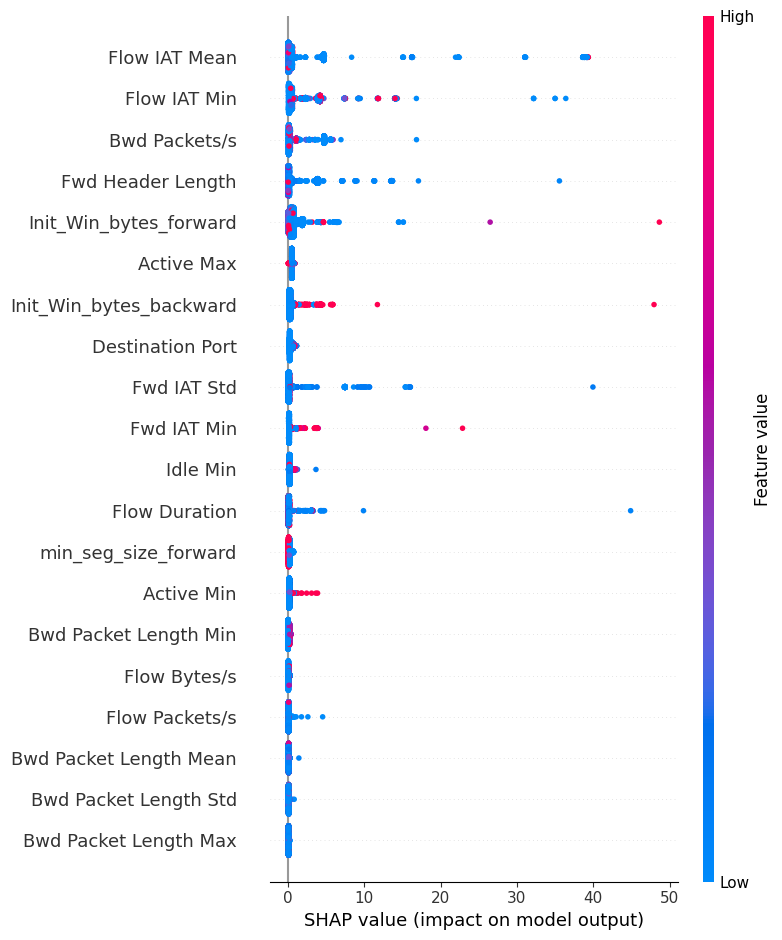

In [12]:
shap_values_mean = np.mean(np.abs(shap_values_global), axis=2)
shap.summary_plot(shap_values_mean, X_sample)


=== SHAP Summary: BENIGN ===


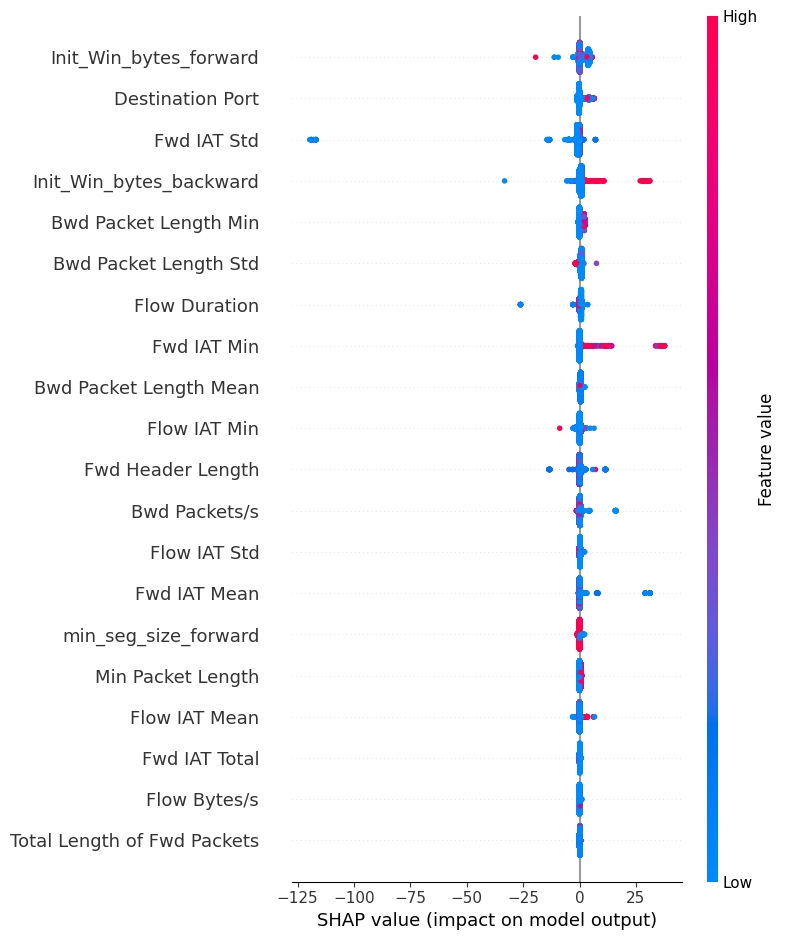


=== SHAP Summary: DoS Hulk ===


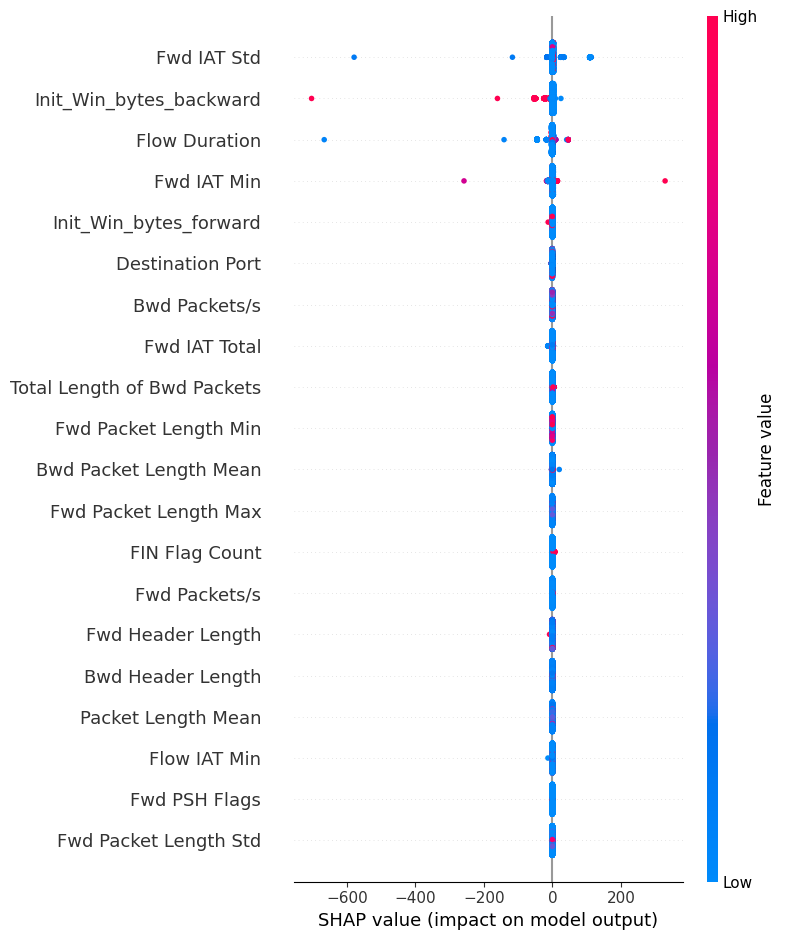


=== SHAP Summary: PortScan ===


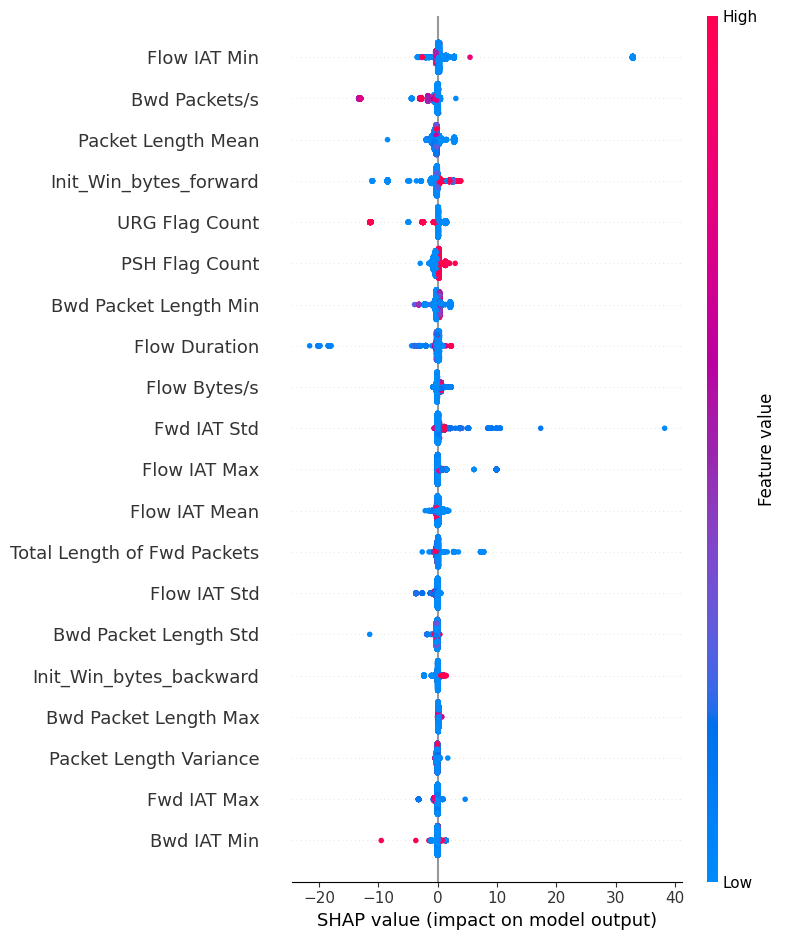


=== SHAP Summary: Bot ===


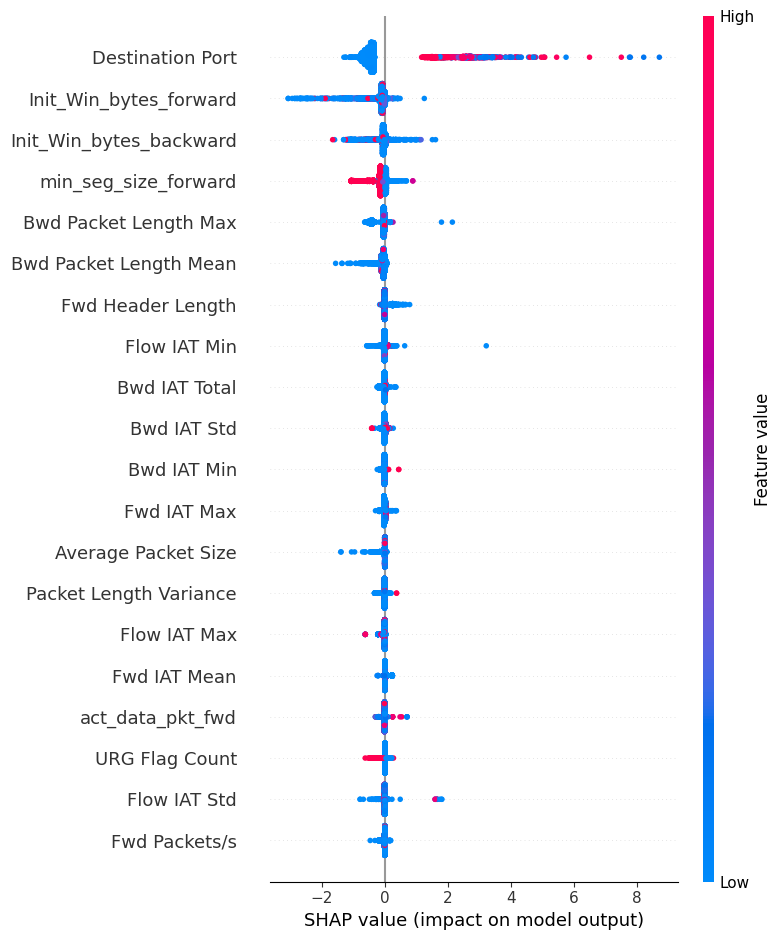

In [13]:
CLASSES_TO_PLOT = ['BENIGN', 'DoS Hulk', 'PortScan', 'Bot']

for label in CLASSES_TO_PLOT:
    class_idx = label_names.index(label)
    print(f'\n=== SHAP Summary: {label} ===')
    shap.summary_plot(
        shap_values_global[:, :, class_idx],
        X_sample,
        show=True
    )

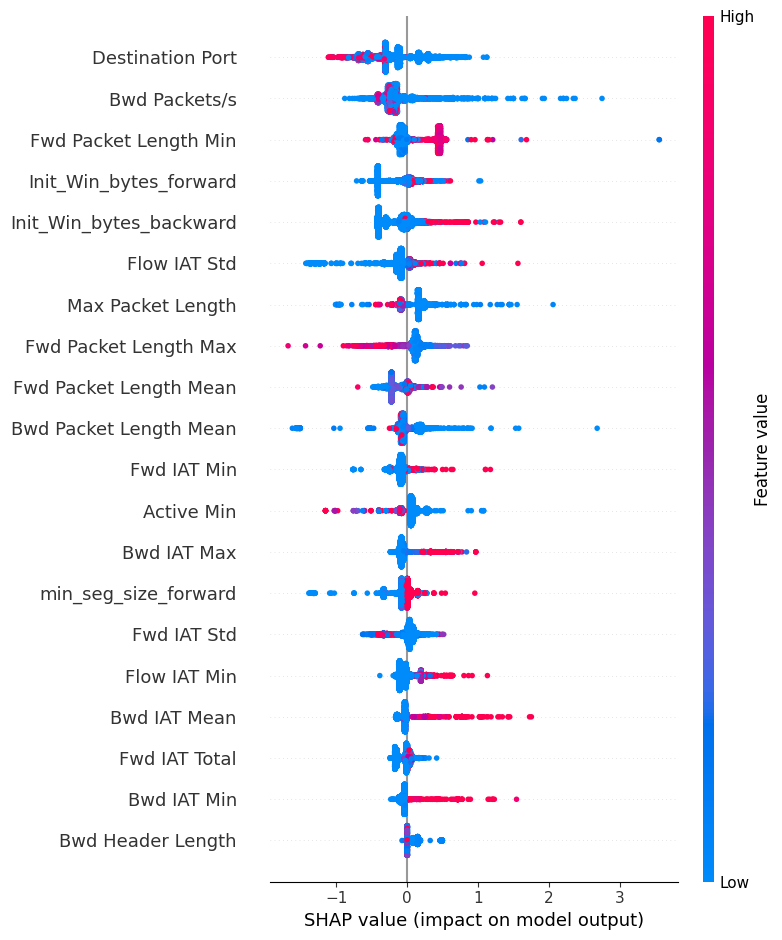

In [14]:
class_idx = label_names.index('DoS slowloris')
shap.summary_plot(shap_values_global[:, :, class_idx], X_sample)

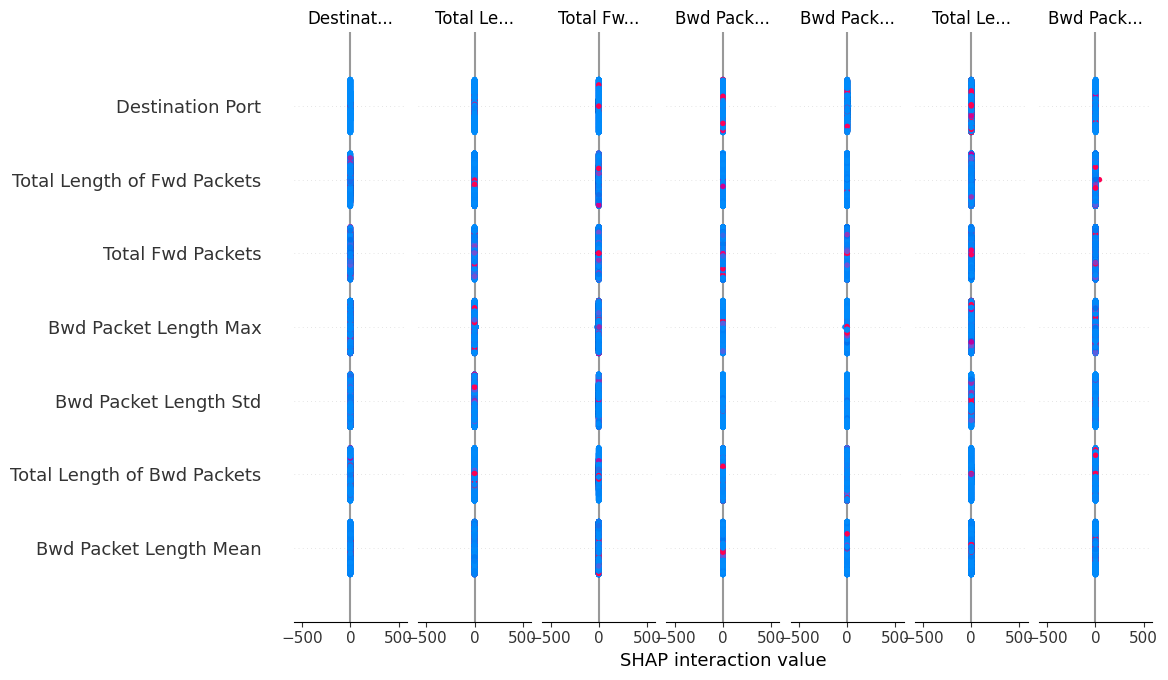

In [15]:
shap.summary_plot(shap_values_global, X_sample)

In [16]:
os.makedirs('models', exist_ok=True)
joblib.dump(explainer, 'models/shap_explainer.pkl')
print('✅ models/shap_explainer.pkl saved')

✅ models/shap_explainer.pkl saved


In [17]:
PRESET_FEATURES = [
    'Flow IAT Mean', 'Flow IAT Min', 'Bwd Packets/s',
    'Fwd Header Length', 'Init_Win_bytes_forward', 'Active Max',
    'Init_Win_bytes_backward', 'Destination Port',
    'Fwd IAT Std', 'Flow Duration', 'min_seg_size_forward',
]

print('=== Median values per kelas ===')
for label in ['BENIGN', 'DoS Hulk', 'PortScan', 'Bot']:
    subset = df[df['Label'] == label].drop(columns=['Label'])
    subset = subset.replace([np.inf, -np.inf], np.nan).fillna(0)
    row    = subset.median()
    print(f'\n--- {label} ---')
    for feat in PRESET_FEATURES:
        print(f'  {feat:<35}: {row[feat]}')

=== Median values per kelas ===

--- BENIGN ---
  Flow IAT Mean                      : 10575.0
  Flow IAT Min                       : 4.0
  Bwd Packets/s                      : 25.40756917
  Fwd Header Length                  : 64.0
  Init_Win_bytes_forward             : 118.0
  Active Max                         : 0.0
  Init_Win_bytes_backward            : -1.0
  Destination Port                   : 80.0
  Fwd IAT Std                        : 0.0
  Flow Duration                      : 30996.0
  min_seg_size_forward               : 20.0

--- DoS Hulk ---
  Flow IAT Mean                      : 6595611.385
  Flow IAT Min                       : 2.0
  Bwd Packets/s                      : 0.060771929
  Fwd Header Length                  : 164.0
  Init_Win_bytes_forward             : 251.0
  Active Max                         : 8.0
  Init_Win_bytes_backward            : 235.0
  Destination Port                   : 80.0
  Fwd IAT Std                        : 33100000.0
  Flow Duration       

In [18]:
print('=== First-row values per kelas ===')
for label in ['DoS Hulk', 'PortScan', 'BENIGN', 'Bot']:
    sample = df[df['Label'] == label].iloc[0]
    print(f'\n--- {label} ---')
    for feat in PRESET_FEATURES:
        print(f'  {feat:<35}: {sample[feat]}')

=== First-row values per kelas ===

--- DoS Hulk ---
  Flow IAT Mean                      : 234.75
  Flow IAT Min                       : 15
  Bwd Packets/s                      : 3194.888179
  Fwd Header Length                  : 104
  Init_Win_bytes_forward             : 29200
  Active Max                         : 0
  Init_Win_bytes_backward            : 235
  Destination Port                   : 80
  Fwd IAT Std                        : 265.1650429
  Flow Duration                      : 1878
  min_seg_size_forward               : 32

--- PortScan ---
  Flow IAT Mean                      : 502105.9
  Flow IAT Min                       : 19
  Bwd Packets/s                      : 0.995805865
  Fwd Header Length                  : 200
  Init_Win_bytes_forward             : 29200
  Active Max                         : 0
  Init_Win_bytes_backward            : 243
  Destination Port                   : 80
  Fwd IAT Std                        : 17612.66701
  Flow Duration                  